# Student Performance Indicator
## 🚀 End-to-End Machine Learning Project Lifecycle

This notebook walks through the complete lifecycle of a Machine Learning project, structured step-by-step from problem definition to model selection.

---

 ### Life cycle of Machine learning Project
  - Understanding the Problem Statement
  - Data Collection
  - Data Checks to perform
  - Exploratory data analysis
  - Data Pre-Processing
   -Model Training
  - Choose best model

 ### 1) Problem statement
This project understands how the student's performance (test scores) is affected by other variables such as Gender, Ethnicity, Parental level of education, Lunch and Test preparation course.

### 2) Data Collection
- Dataset Source - https://www.kaggle.com/datasets/spscientist/students-performance-in-exams?datasetId=74977
- The data consists of 8 column and 1000 rows.

## 2.1 Import Data and Required Packages
Importing Pandas, Numpy, Matplotlib, Seaborn and Warings Library.

In [762]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

### Import the CSV Data as Pandas DataFrame

In [763]:
df = pd.read_csv('data.csv')

### show top 5 record

In [764]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### show botom 5 record

In [765]:
df.tail()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


### 
Shape of the dataset

In [766]:
df.shape

(1000, 8)

## 2.2 Dataset information
- gender : sex of students -> (Male/female)
- race/ethnicity : ethnicity of students -> (Group A, B,C, D,E)
- parental level of education : parents' final education ->(bachelor's degree,some college,master's degree,associate's degree,high school)
- lunch : having lunch before test (standard or free/reduced)
- test preparation course : complete or not complete before test
- math score
- reading score
- writing score

### 3. Data Checks to perform
- Check Missing values
- Check Duplicates
- Check data type
- Check the number of unique values of each column
- Check statistics of data set
- Check various categories present in the different categorical column

### 3.1 Check Missing Value

In [767]:
df.isnull().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

### there is no missing value

### 3.2 Check Duplicates

In [768]:
df.duplicated().sum()

np.int64(0)

### 3.3 Check data types

In [769]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


### 3.4 Checking the number of unique values of each column

In [770]:
df.nunique()

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

### 3.5 Check statistics of data set

In [771]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


### Insight
- From above description of numerical data, all means are very close to each other - between 66 and 68.05;
- All standard deviations are also close - between 14.6 and 15.19;
- While there is a minimum score 0 for math, for writing minimum is much higher = 10 and for reading myet higher = 17

### 3.7 Exploring Data

In [772]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [773]:
print("category in 'gender' column:",end=' ')
print(df['gender'].unique().tolist())
print("category in parental level of education column:",end=' ')
print(df['parental_level_of_education'].unique().tolist())
print("category in lunch column:",end=' ')
print(df['lunch'].unique().tolist())
print("category in test preparation course column:",end=' ')
print(df['test_preparation_course'].unique().tolist())

category in 'gender' column: ['female', 'male']
category in parental level of education column: ["bachelor's degree", 'some college', "master's degree", "associate's degree", 'high school', 'some high school']
category in lunch column: ['standard', 'free/reduced']
category in test preparation course column: ['none', 'completed']


In [774]:
# define numerical & categorical columns
numerical_columns = [feature for feature in df.columns if df[feature].dtypes != 'O']
categorical_columns = [feature for feature in df.columns if df[feature].dtypes == 'O']
# Get numerical columns (integers and floats only)
numerical_columns = df.select_dtypes(include=['number']).columns.tolist()

# Get categorical columns (objects, categories, and string arrays)
categorical_columns = df.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

In [775]:
# print numerical & categorical columns
print('we have {} numerical columns : {}'.format(len(numerical_columns),numerical_columns))
print('we have {} categorical columns : {}'.format(len(categorical_columns),categorical_columns))

we have 3 numerical columns : ['math_score', 'reading_score', 'writing_score']
we have 5 categorical columns : ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


### 3.8 Adding columns for "Total Score" and "Average"

In [776]:
df['total_score'] = df['math_score'] + df['reading_score'] + df['writing_score']
df['average_score'] = df['total_score'] / 3

In [777]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [778]:
reading_full = df[df["reading_score"] == 100]['average_score'].count()
writing_full = df[df["writing_score"] == 100]['average_score'].count()
math_full = df[df["math_score"] == 100]['average_score'].count()

In [779]:
print(f"Number of students with full marks in reading: {reading_full}")
print(f"Number of students with full marks in writing: {writing_full}")
print(f"Number of students with full marks in math: {math_full}")

Number of students with full marks in reading: 17
Number of students with full marks in writing: 14
Number of students with full marks in math: 7


In [780]:
reading_less_30 = df[df["reading_score"] < 30]['average_score'].count()
writing_less_30 = df[df["writing_score"] < 30]['average_score'].count()
math_less_30 = df[df["math_score"] < 30]['average_score'].count()

In [781]:
print(f"Number of students with scores less than 30 in reading: {reading_less_30}")
print(f"Number of students with scores less than 30 in writing: {writing_less_30}")
print(f"Number of students with scores less than 30 in math: {math_less_30}")

Number of students with scores less than 30 in reading: 8
Number of students with scores less than 30 in writing: 9
Number of students with scores less than 30 in math: 14


### Insights
- From above values we get students have performed the worst in Maths
- Best performance is in reading section

## 4. Exploring Data ( Visualization )
### 4.1 Visualize average score distribution to make some conclusion.
- Histogram
- Kernel Distribution Function (KDE)

### 4.1.1 Histogram & KDE

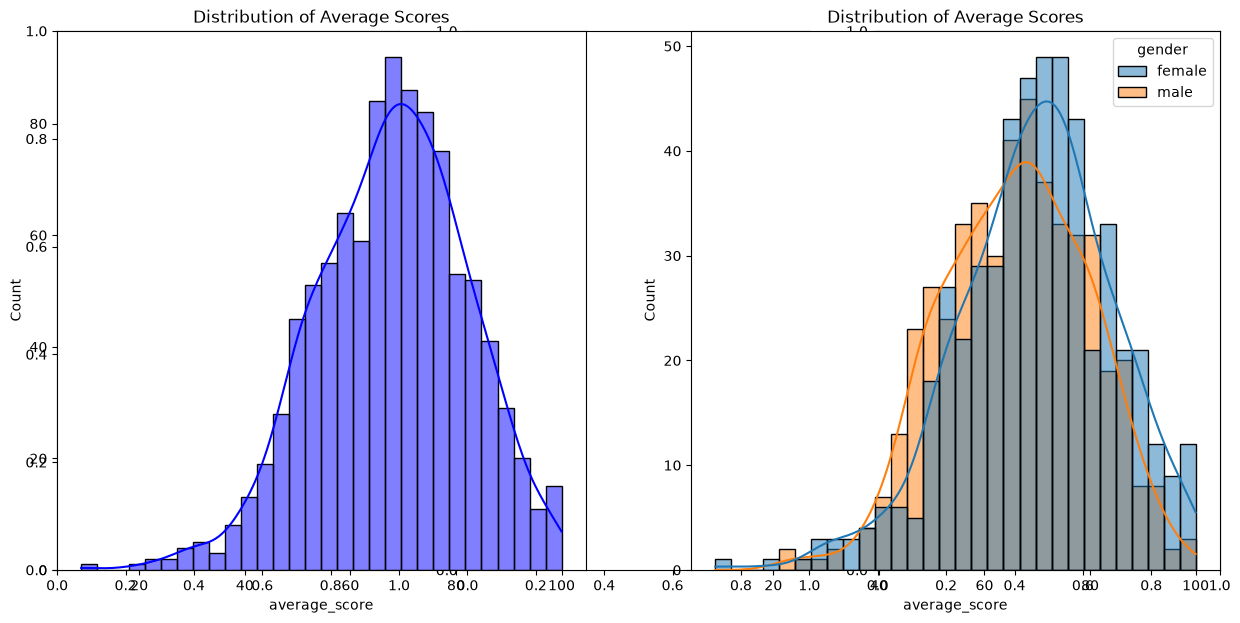

In [782]:
fig, axes = plt.subplots(1, 3, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data = df, x = 'average_score', kde=True, color='blue', bins=30)
plt.title('Distribution of Average Scores')
plt.subplot(122)
sns.histplot(data = df, x = 'average_score', kde=True, hue='gender', bins=30)
plt.title('Distribution of Average Scores')
plt.show()

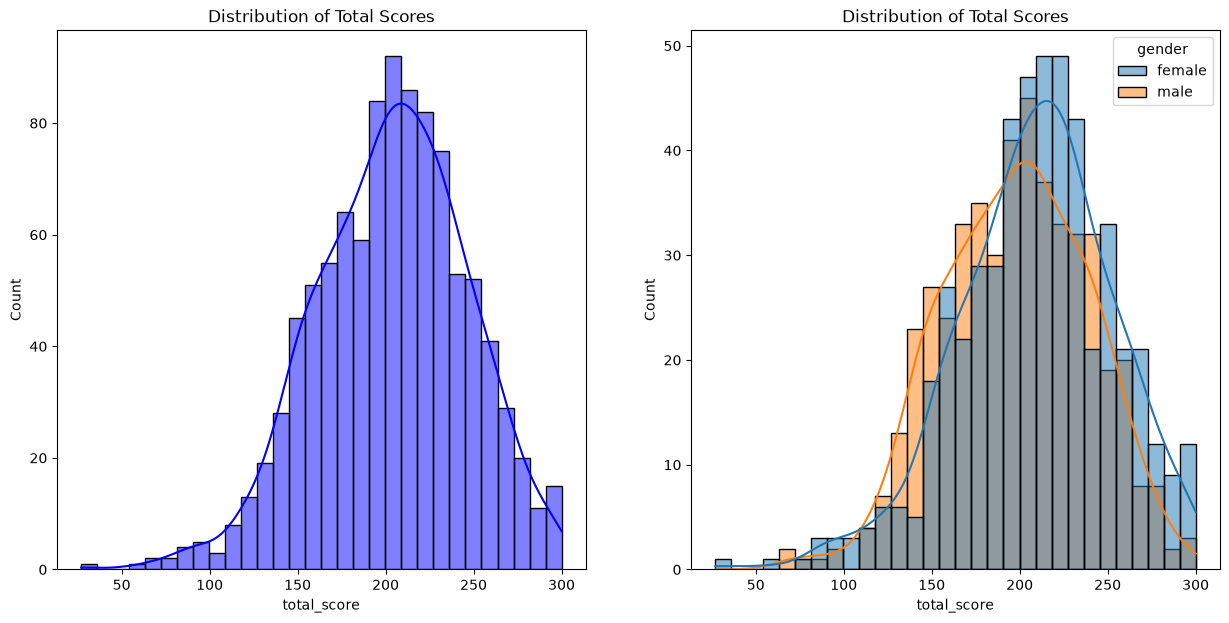

In [783]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data = df, x = 'total_score', kde=True, color='blue', bins=30)
plt.title('Distribution of Total Scores')
plt.subplot(122)
sns.histplot(data = df, x = 'total_score', kde=True, hue='gender', bins=30)
plt.title('Distribution of Total Scores')
plt.show()

### Insights
Female students tend to perform well then male students.

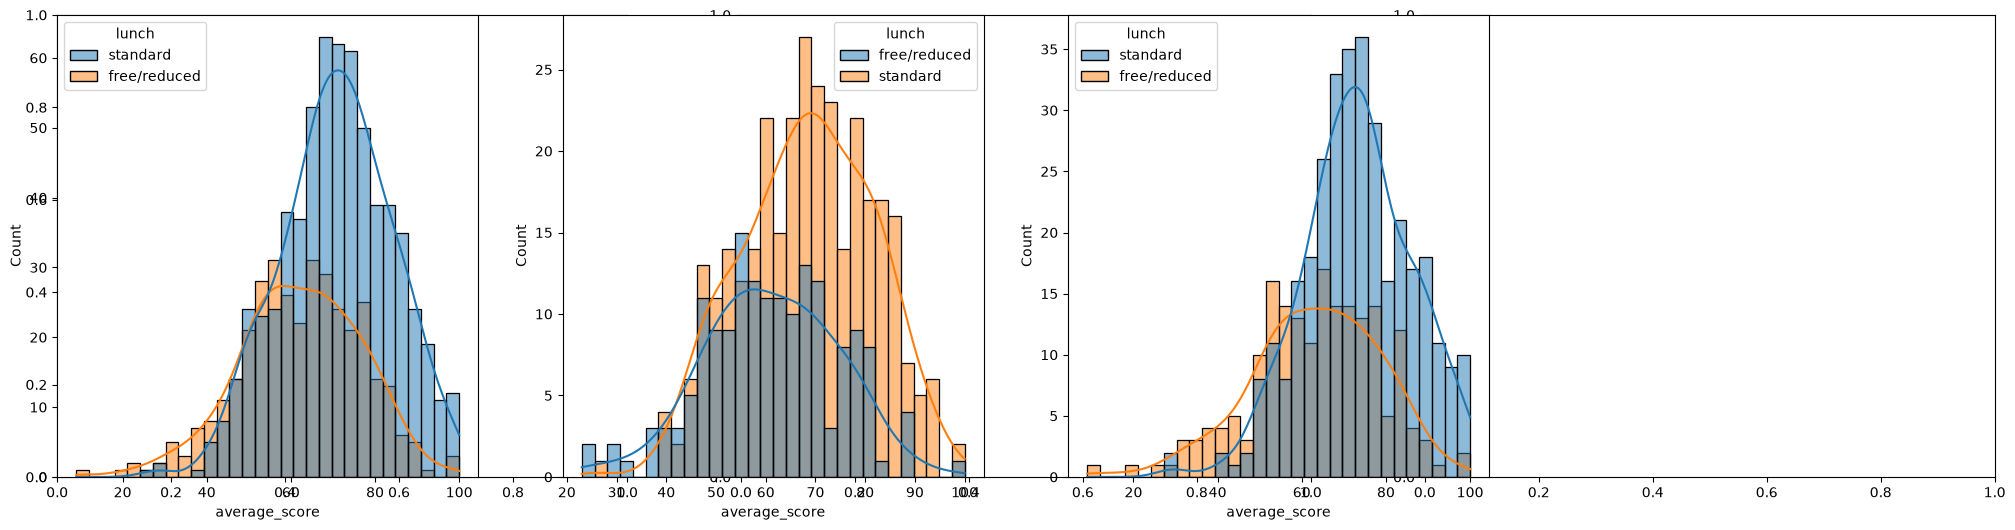

In [784]:
plt.subplots(1,3,figsize=(25,6))
plt.subplot(141)
sns.histplot(data = df, x = 'average_score', kde=True, hue = 'lunch', color='blue', bins=30)
plt.subplot(142)
sns.histplot(data = df[df.gender == 'male'], x = 'average_score', kde=True, hue = 'lunch', color='blue', bins=30)
plt.subplot(143)
sns.histplot(data = df[df.gender == 'female'], x = 'average_score', kde=True, hue = 'lunch', color='blue', bins=30)
plt.show()

## Insights
- Standard lunch helps perform well in exams.
- Standard lunch helps perform well in exams be it a male or a female.

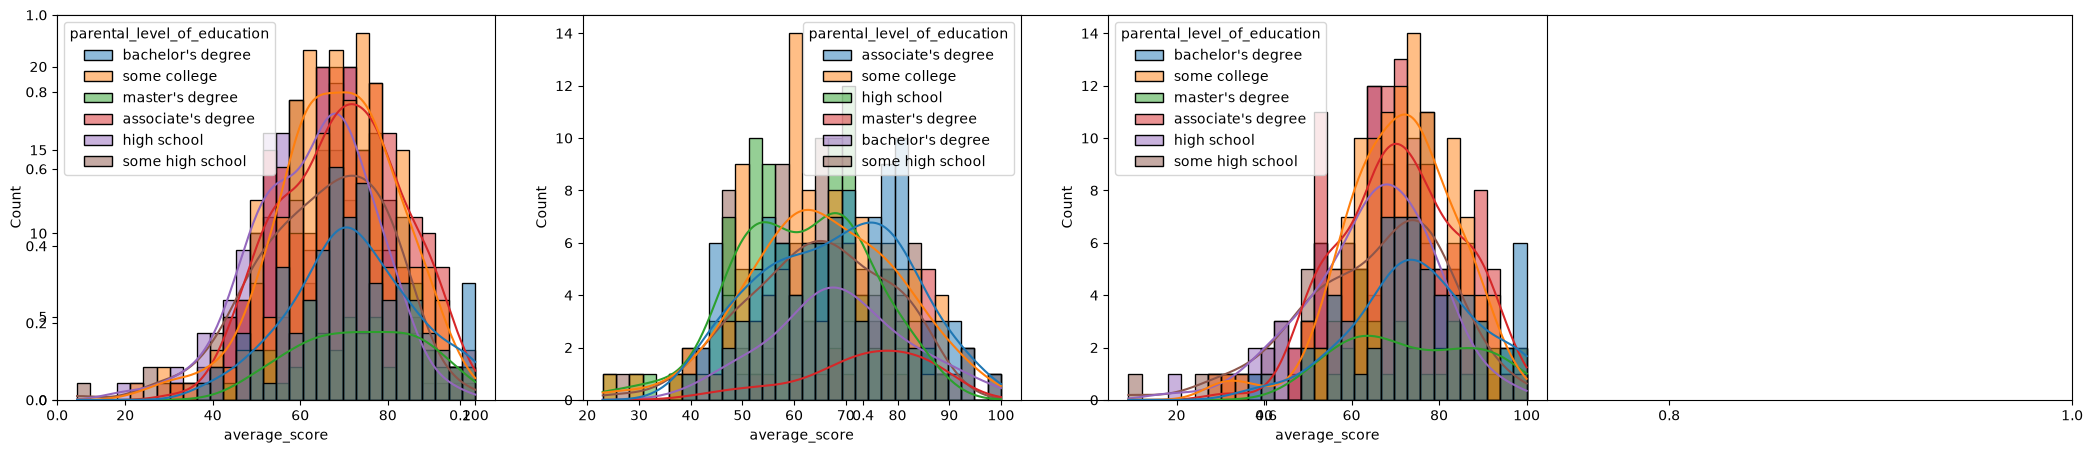

In [785]:
plt.subplots(figsize=(26, 5))
plt.subplot(141)
sns.histplot(data = df, x = 'average_score', kde=True, hue = 'parental_level_of_education', color='blue', bins=30)
plt.subplot(142)
sns.histplot(data = df[df.gender == 'male'], x = 'average_score', kde=True, hue = 'parental_level_of_education', color='blue', bins=30)
plt.subplot(143)
sns.histplot(data = df[df.gender == 'female'], x = 'average_score', kde=True, hue = 'parental_level_of_education', color='blue', bins=30)
plt.show()


### Insights
- In general parent's education don't help student perform well in exam.
- 2nd plot shows that parent's whose education is of associate's degree or master's degree their male child tend to perform well in exam
- 3rd plot we can see there is no effect of parent's education on female students.

In [786]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


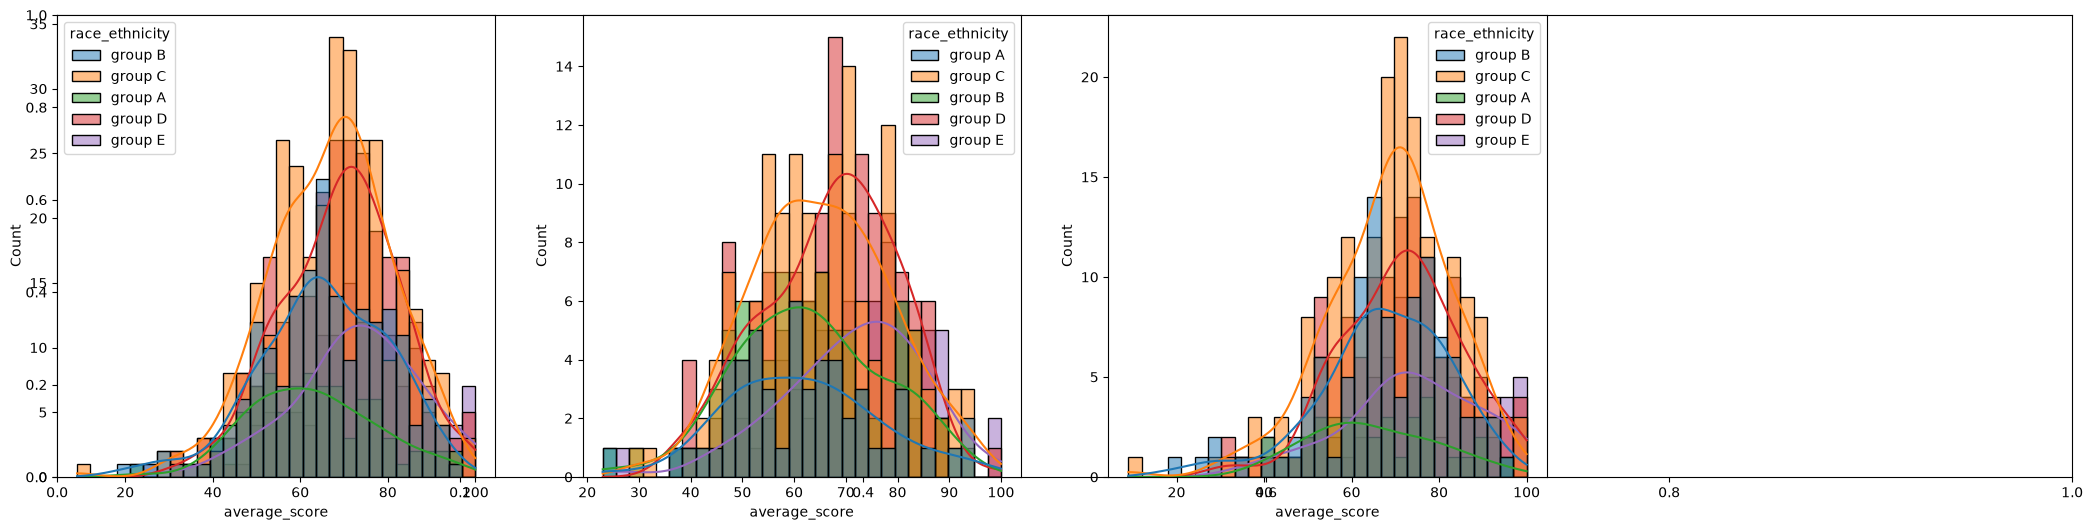

In [787]:
plt.subplots(figsize=(26, 6))
plt.subplot(141)
sns.histplot(data = df, x = 'average_score', kde=True, hue = 'race_ethnicity', color='blue', bins=30)
plt.subplot(142)
sns.histplot(data = df[df.gender == 'male'], x = 'average_score', kde=True, hue = 'race_ethnicity', color='blue', bins=30)
plt.subplot(143)
sns.histplot(data = df[df.gender == 'female'], x = 'average_score', kde=True, hue = 'race_ethnicity', color='blue', bins=30)
plt.show()

### Insights
- Students of group A and group B tends to perform poorly in exam.
- Students of group A and group B tends to perform poorly in exam irrespective of whether they are male or female

## 4.2 Maximumum score of students in all three subjects

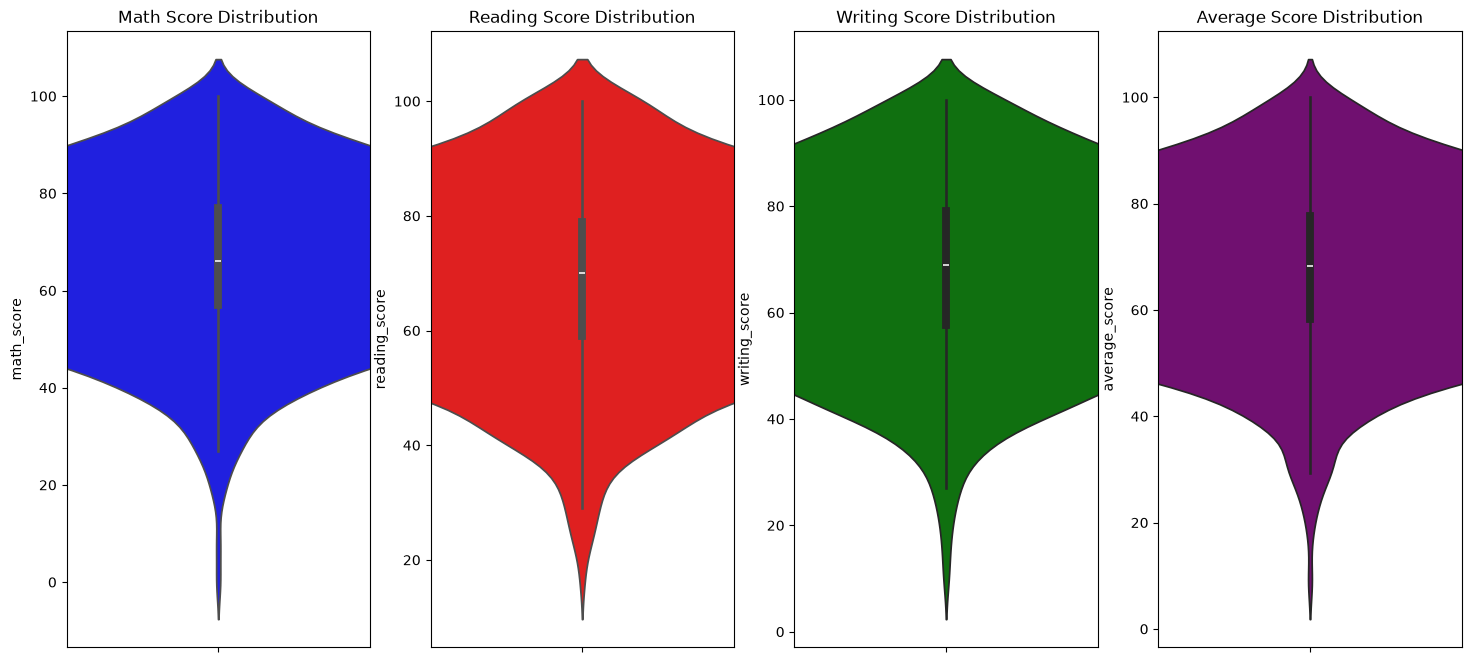

In [788]:
plt.figure(figsize=(18,8))
plt.subplot(1,4,1)
plt.title('Math Score Distribution')
sns.violinplot(y='math_score', data=df , color='blue',width=3)
plt.subplot(1,4,2)
plt.title('Reading Score Distribution')
sns.violinplot(y='reading_score', data=df , color='red',width=3)
plt.subplot(1,4,3)
plt.title('Writing Score Distribution')
sns.violinplot(y='writing_score', data=df , color='green',width=3)
plt.subplot(1,4,4)
plt.title('Average Score Distribution')
sns.violinplot(y='average_score', data=df , color='purple',width=3)
plt.show()

### 4.3 Multivariate analysis using pieplot

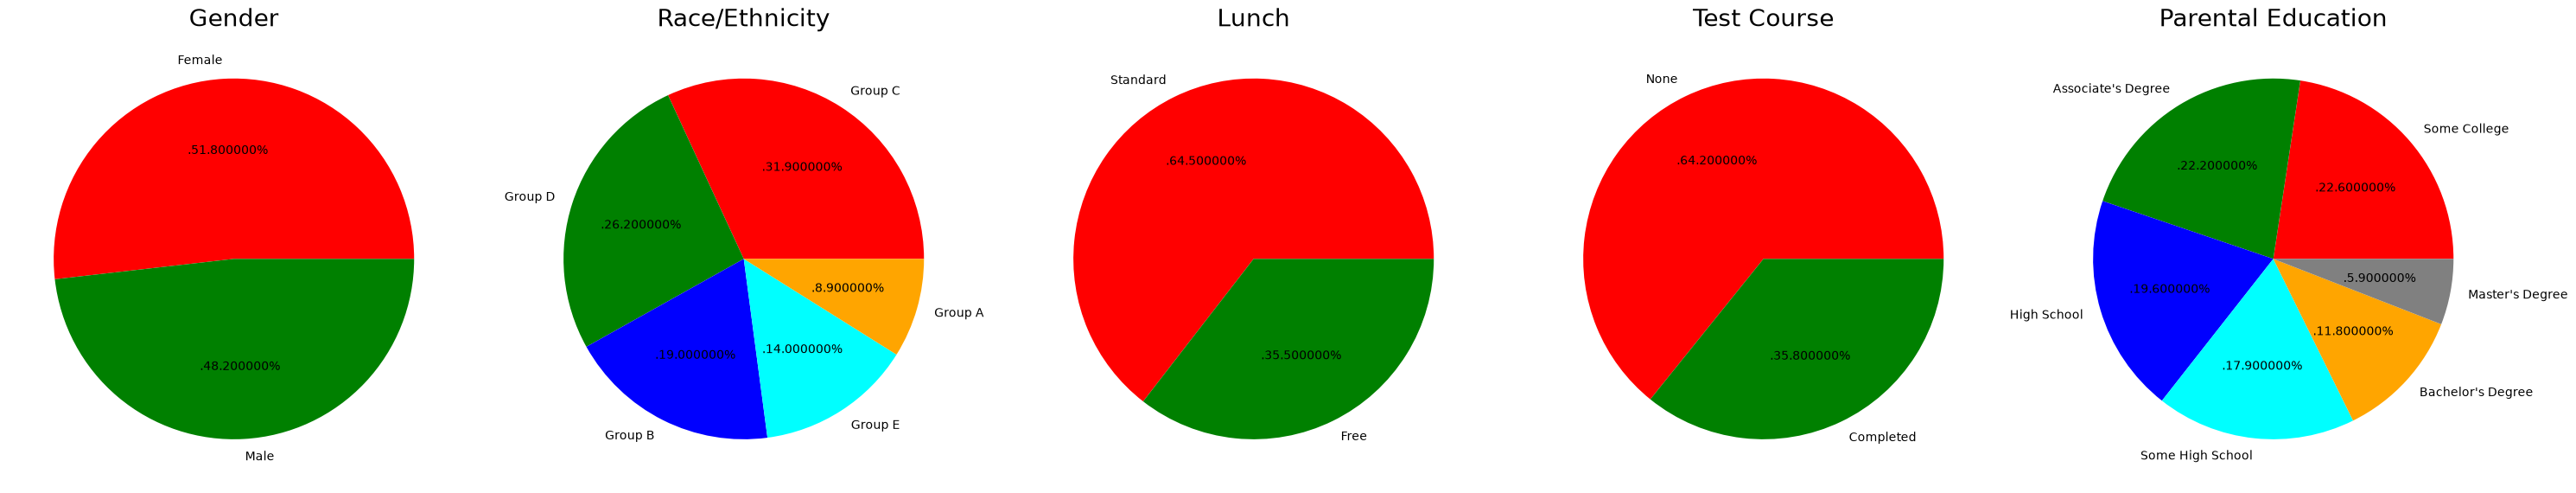

In [789]:

plt.rcParams['figure.figsize'] = (30, 12)

plt.subplot(1, 5, 1)
size = df['gender'].value_counts()
labels = 'Female', 'Male'
color = ['red','green']


plt.pie(size, colors = color, labels = labels,autopct = '.%2f%%')
plt.title('Gender', fontsize = 20)
plt.axis('off')

plt.subplot(1, 5, 2)
size = df['race_ethnicity'].value_counts()
labels = 'Group C', 'Group D','Group B','Group E','Group A'
color = ['red', 'green', 'blue', 'cyan','orange']

plt.pie(size, colors = color,labels = labels,autopct = '.%2f%%')
plt.title('Race/Ethnicity', fontsize = 20)
plt.axis('off')



plt.subplot(1, 5, 3)
size = df['lunch'].value_counts()
labels = 'Standard', 'Free'
color = ['red','green']

plt.pie(size, colors = color,labels = labels,autopct = '.%2f%%')
plt.title('Lunch', fontsize = 20)
plt.axis('off')


plt.subplot(1, 5, 4)
size = df['test_preparation_course'].value_counts()
labels = 'None', 'Completed'
color = ['red','green']

plt.pie(size, colors = color,labels = labels,autopct = '.%2f%%')
plt.title('Test Course', fontsize = 20)
plt.axis('off')


plt.subplot(1, 5, 5)
size = df['parental_level_of_education'].value_counts()
labels = 'Some College', "Associate's Degree",'High School','Some High School',"Bachelor's Degree","Master's Degree"
color = ['red', 'green', 'blue', 'cyan','orange','grey']

plt.pie(size, colors = color,labels = labels,autopct = '.%2f%%')
plt.title('Parental Education', fontsize = 20)
plt.axis('off')


plt.tight_layout()
plt.grid()

plt.show()

### Insights
- Number of Male and Female students is almost equal
- Number students are greatest in Group C
- Number of students who have standard lunch are greater
- Number of students who have not enrolled in any test preparation course is greater
- Number of students whose parental education is "Some College" is greater followed closely by "Associate's Degree"

## 4.4 Feature Wise Visualization
### 4.4.1 GENDER COLUMN
- How is distribution of Gender ?
- Is gender has any impact on student's performance ?

## UNIVARIATE ANALYSIS ( How is distribution of Gender ? )

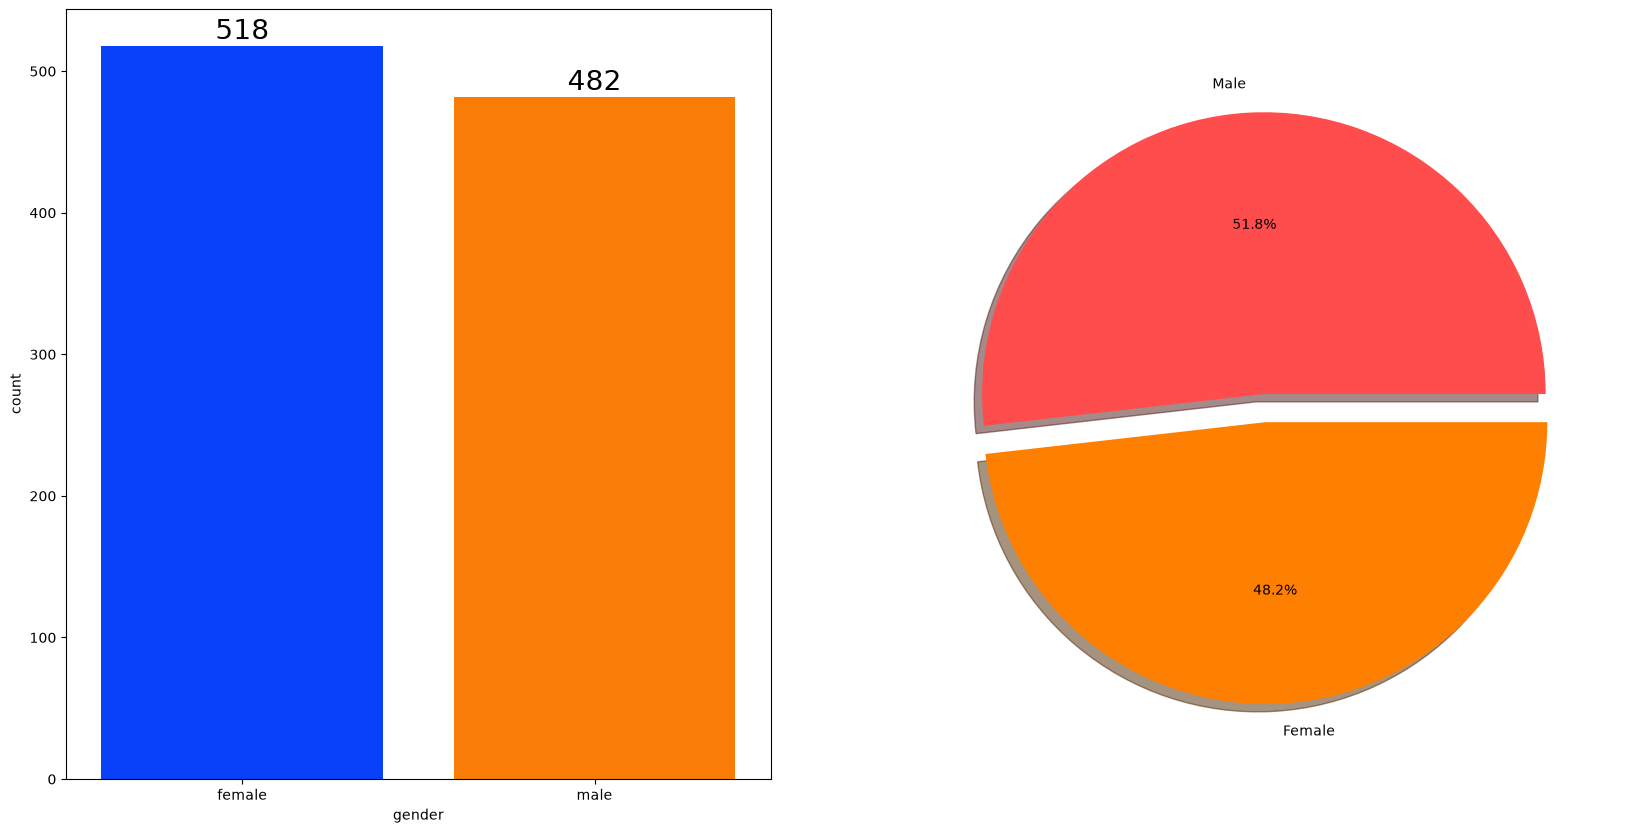

In [790]:
f,ax=plt.subplots(1,2,figsize=(20,10))
sns.countplot(x=df['gender'],data=df,palette ='bright',ax=ax[0],saturation=0.95)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)
    
plt.pie(x=df['gender'].value_counts(),labels=['Male','Female'],explode=[0,0.1],autopct='%1.1f%%',shadow=True,colors=['#ff4d4d','#ff8000'])
plt.show()

### Insights
- Gender has balanced data with female students are 518 (48%) and male students are 482 (52%)

## BIVARIATE ANALYSIS ( Is gender has any impact on student's performance ? )

In [791]:
gender_grouped = df.groupby('gender')
gender_grouped

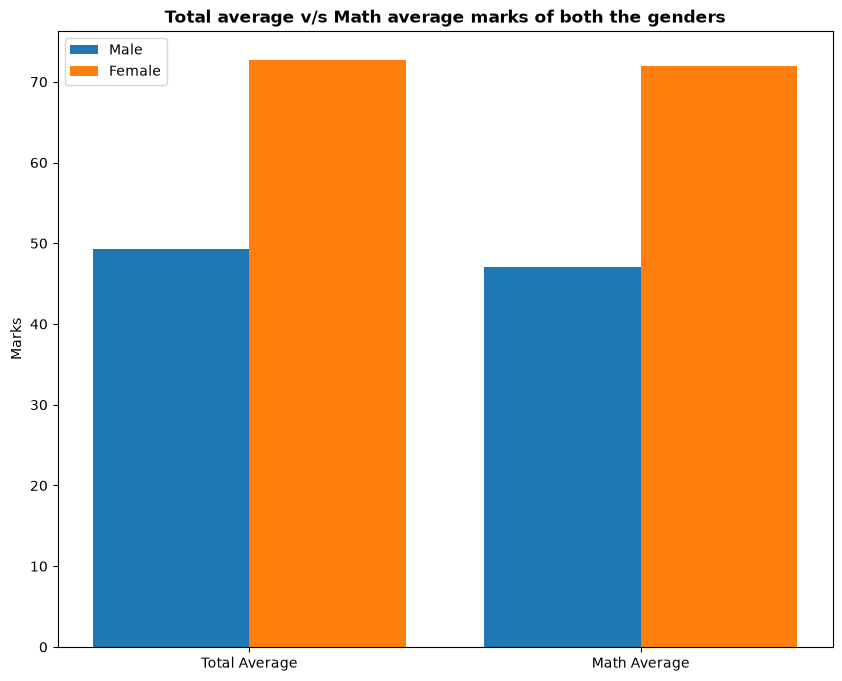

In [792]:
plt.figure(figsize=(10, 8))

X = ['Total Average','Math Average']


female_scores = [gender_grouped.get_group('female')['average_score'].iloc[0], gender_grouped.get_group('female')['math_score'].iloc[0]]
male_scores = [gender_grouped.get_group('male')['average_score'].iloc[0], gender_grouped.get_group('male')['math_score'].iloc[0]]

X_axis = np.arange(len(X))
  
plt.bar(X_axis - 0.2, male_scores, 0.4, label = 'Male')
plt.bar(X_axis + 0.2, female_scores, 0.4, label = 'Female')
  
plt.xticks(X_axis, X)
plt.ylabel("Marks")
plt.title("Total average v/s Math average marks of both the genders", fontweight='bold')
plt.legend()
plt.show()

### Insights
- On an average females have a better overall score than men.
- whereas males have scored higher in Maths.

### 4.4.2 RACE/EHNICITY COLUMN
- How is Group wise distribution ?
- Is Race/Ehnicity has any impact on student's performance ?


## UNIVARIATE ANALYSIS ( How is Group wise distribution ?)

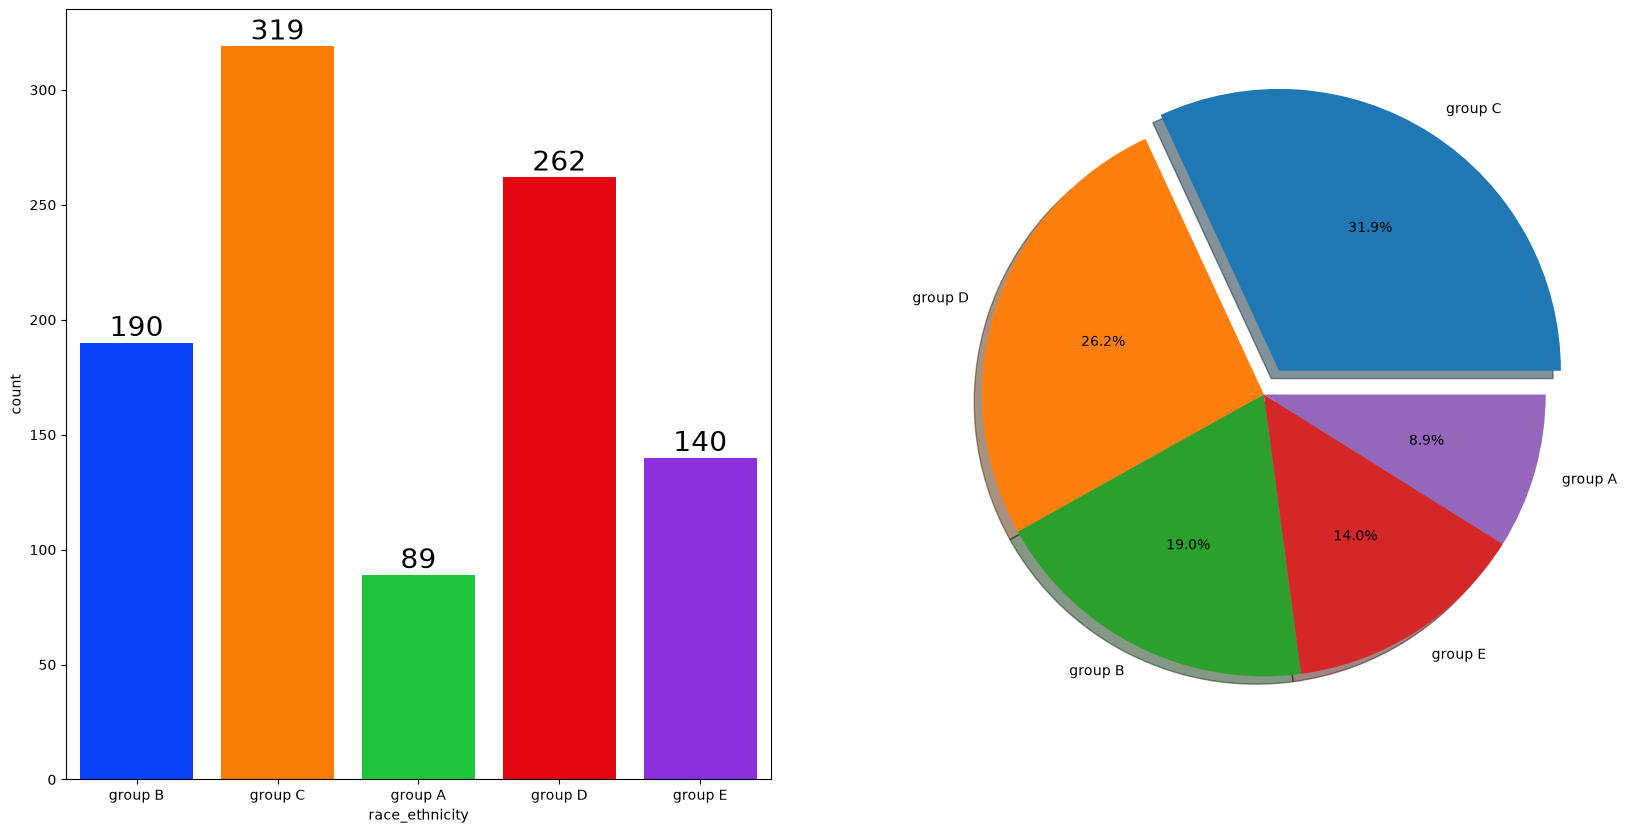

In [793]:
f,ax=plt.subplots(1,2,figsize=(20,10))
sns.countplot(x=df['race_ethnicity'],data=df,palette = 'bright',ax=ax[0],saturation=0.95)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)
    
plt.pie(x = df['race_ethnicity'].value_counts(),labels=df['race_ethnicity'].value_counts().index,explode=[0.1,0,0,0,0],autopct='%1.1f%%',shadow=True)
plt.show()   

### Insights
- Most of the student belonging from group C /group D.
- Lowest number of students belong to groupA.


## BIVARIATE ANALYSIS ( Is Race/Ehnicity has any impact on student's performance ? )

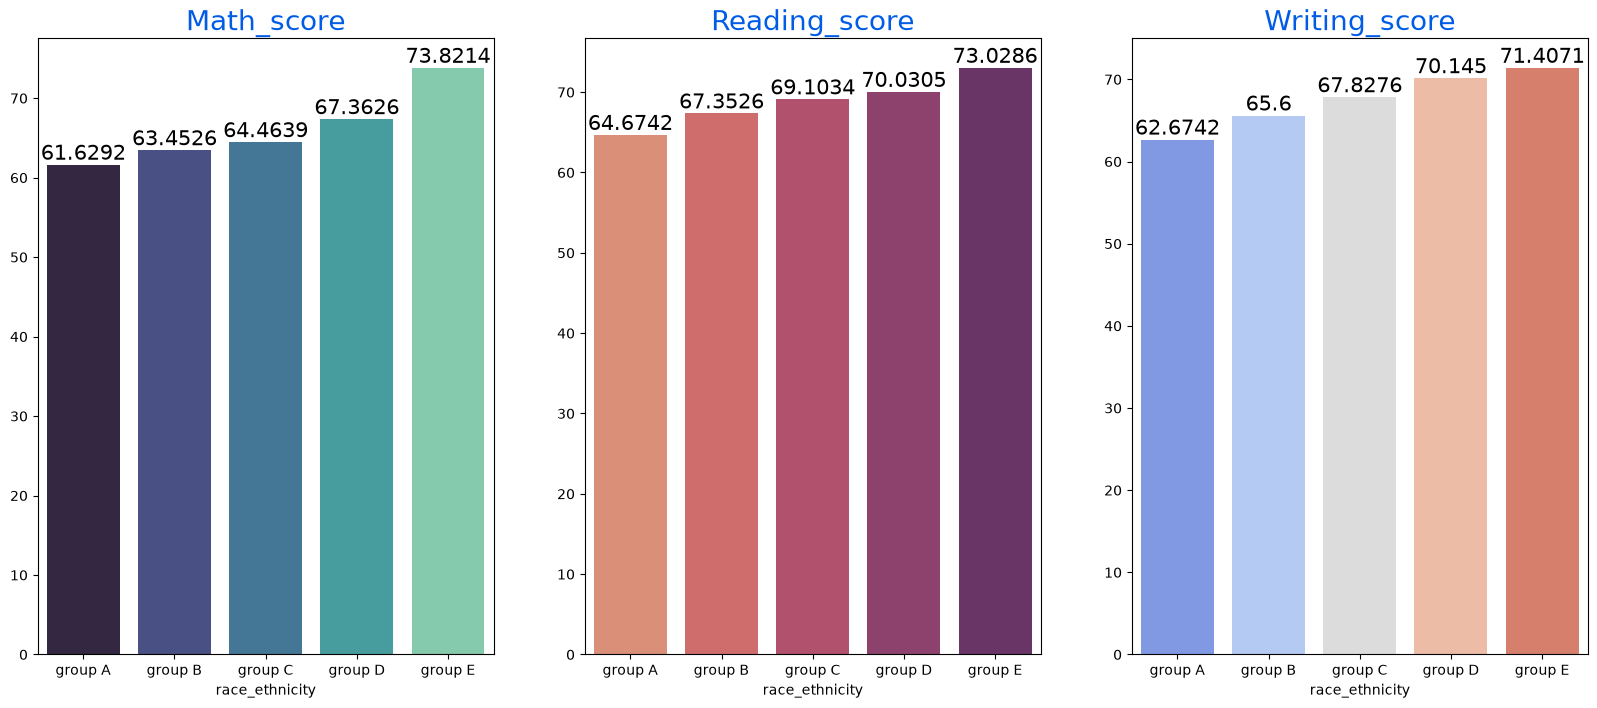

In [794]:
Group_data2=df.groupby('race_ethnicity')
f,ax=plt.subplots(1,3,figsize=(20,8))
sns.barplot(x=Group_data2['math_score'].mean().index,y=Group_data2['math_score'].mean().values,palette = 'mako',ax=ax[0])
ax[0].set_title('Math_score',color='#005ce6',size=20)

for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=15)

sns.barplot(x=Group_data2['reading_score'].mean().index,y=Group_data2['reading_score'].mean().values,palette = 'flare',ax=ax[1])
ax[1].set_title('Reading_score',color='#005ce6',size=20)

for container in ax[1].containers:
    ax[1].bar_label(container,color='black',size=15)

sns.barplot(x=Group_data2['writing_score'].mean().index,y=Group_data2['writing_score'].mean().values,palette = 'coolwarm',ax=ax[2])
ax[2].set_title('Writing_score',color='#005ce6',size=20)

for container in ax[2].containers:
    ax[2].bar_label(container,color='black',size=15)

### Insights
- Group E students have scored the highest marks.
- Group A students have scored the lowest marks.
- Students from a lower Socioeconomic status have a lower avg in all course subjects


## 4.4.3 PARENTAL LEVEL OF EDUCATION COLUMN
- What is educational background of student's parent ?
- Is parental education has any impact on student's performance ?


## UNIVARIATE ANALYSIS ( What is educational background of student's parent ? )

findfont: Failed to find font weight 30 for DejaVu Sans, now using 400.


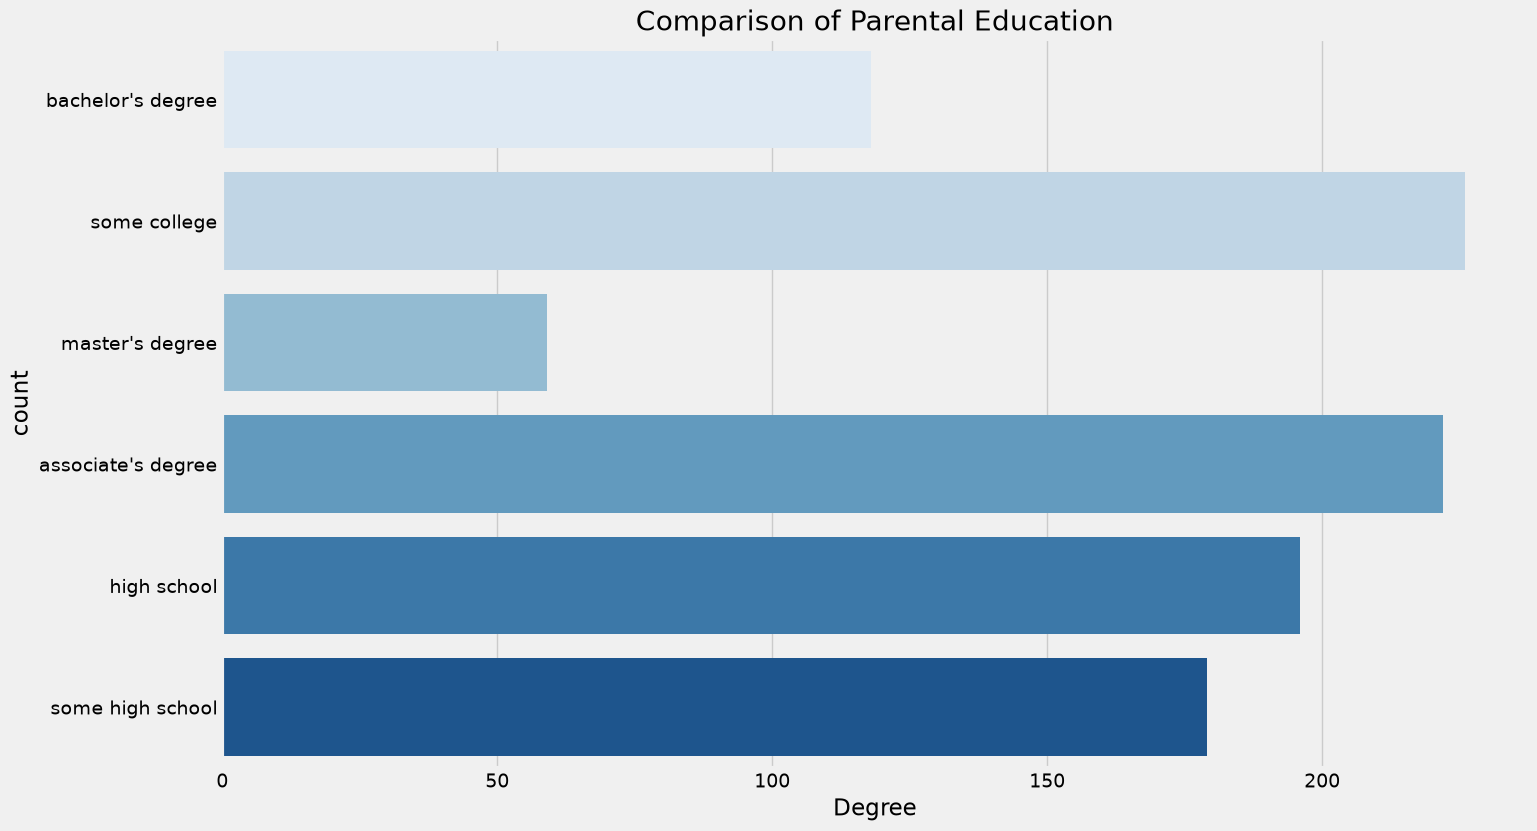

In [796]:
plt.rcParams['figure.figsize'] = (15, 9)
plt.style.use('fivethirtyeight')
sns.countplot(df['parental_level_of_education'], palette = 'Blues')
plt.title('Comparison of Parental Education', fontweight = 30, fontsize = 20)
plt.xlabel('Degree')
plt.ylabel('count')
plt.show()

### Insights
- Largest number of parents are from some college.


## BIVARIATE ANALYSIS ( Is parental education has any impact on student's performance ? )

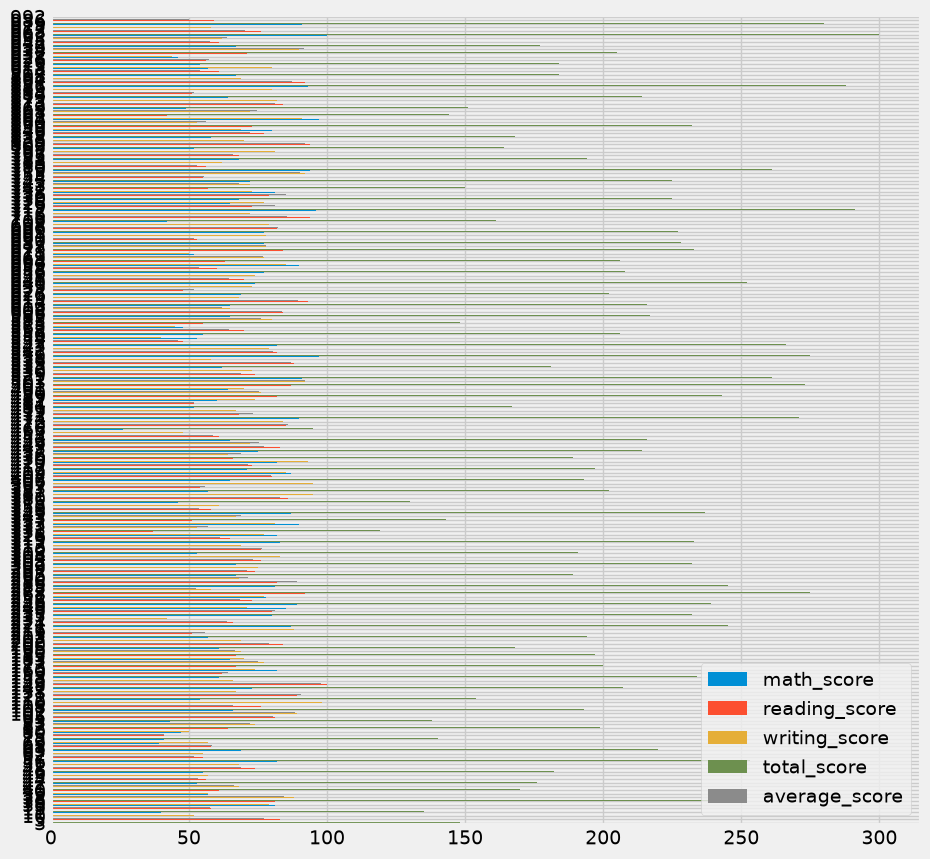

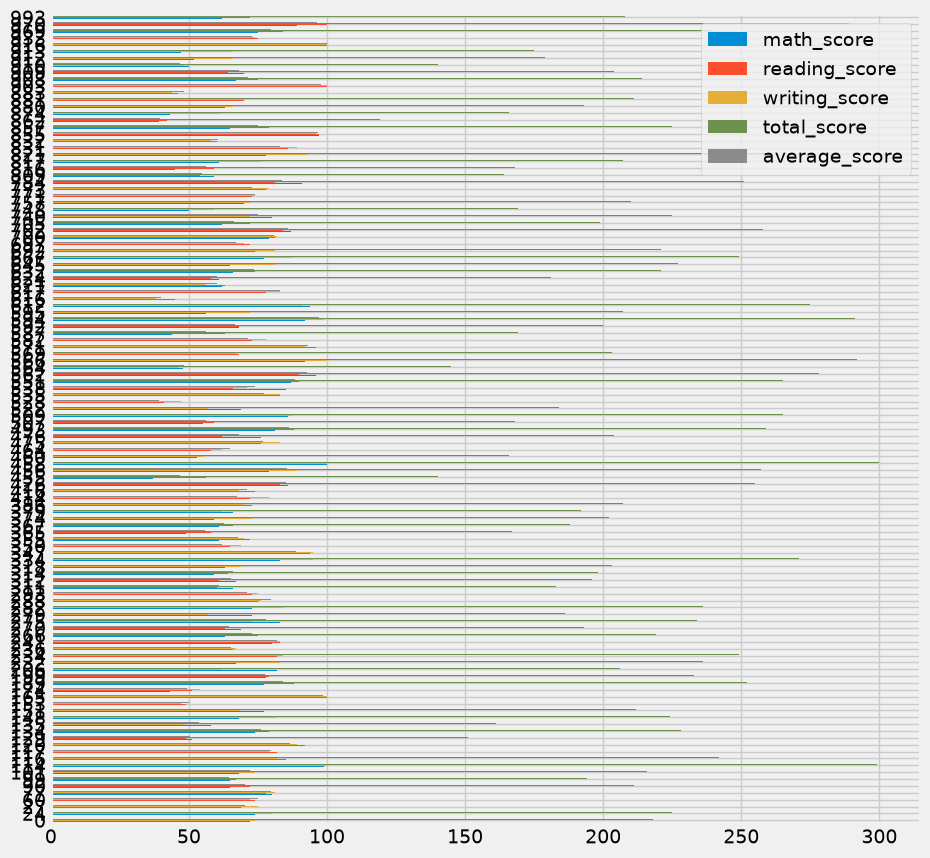

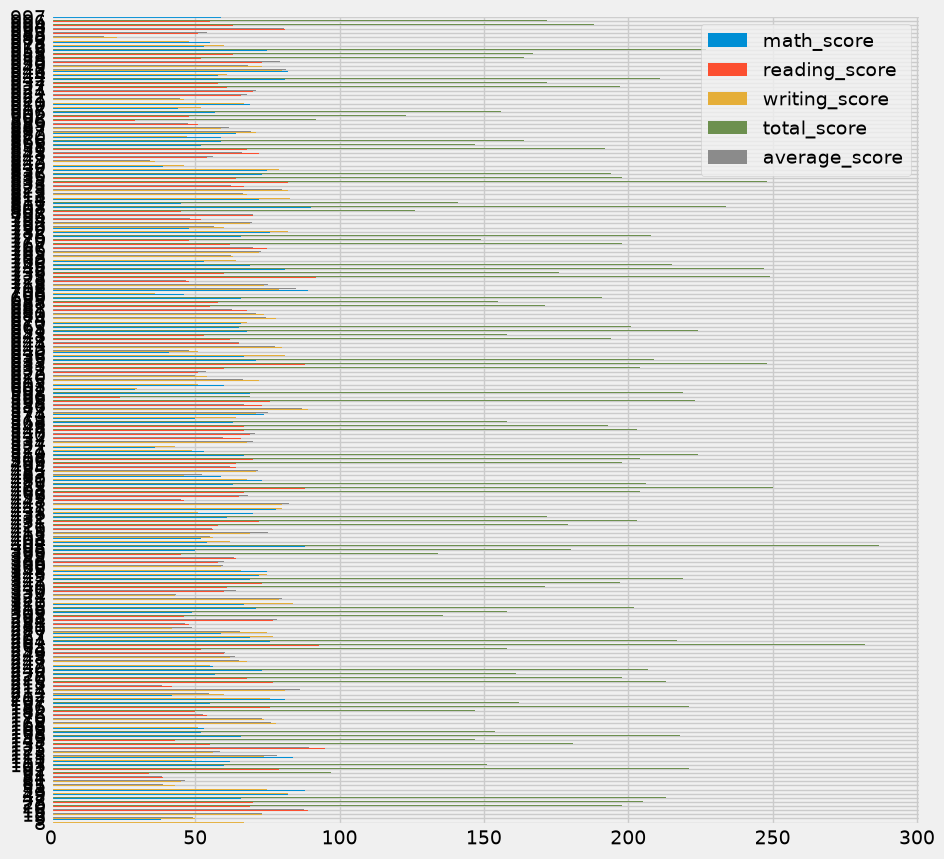

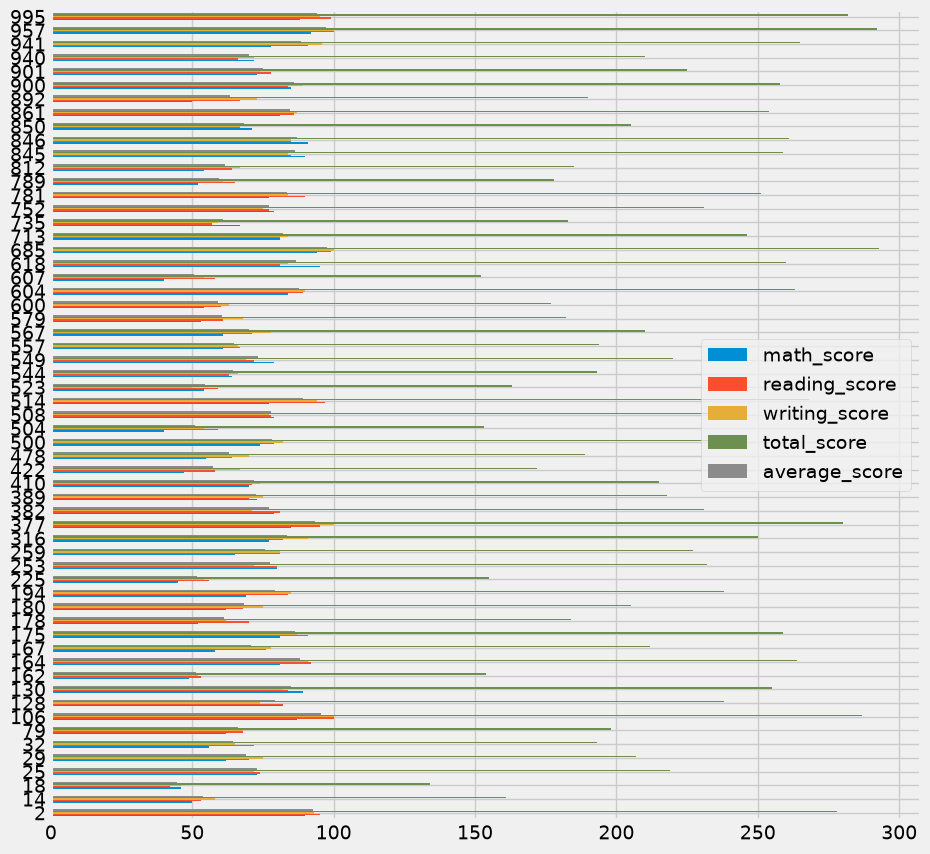

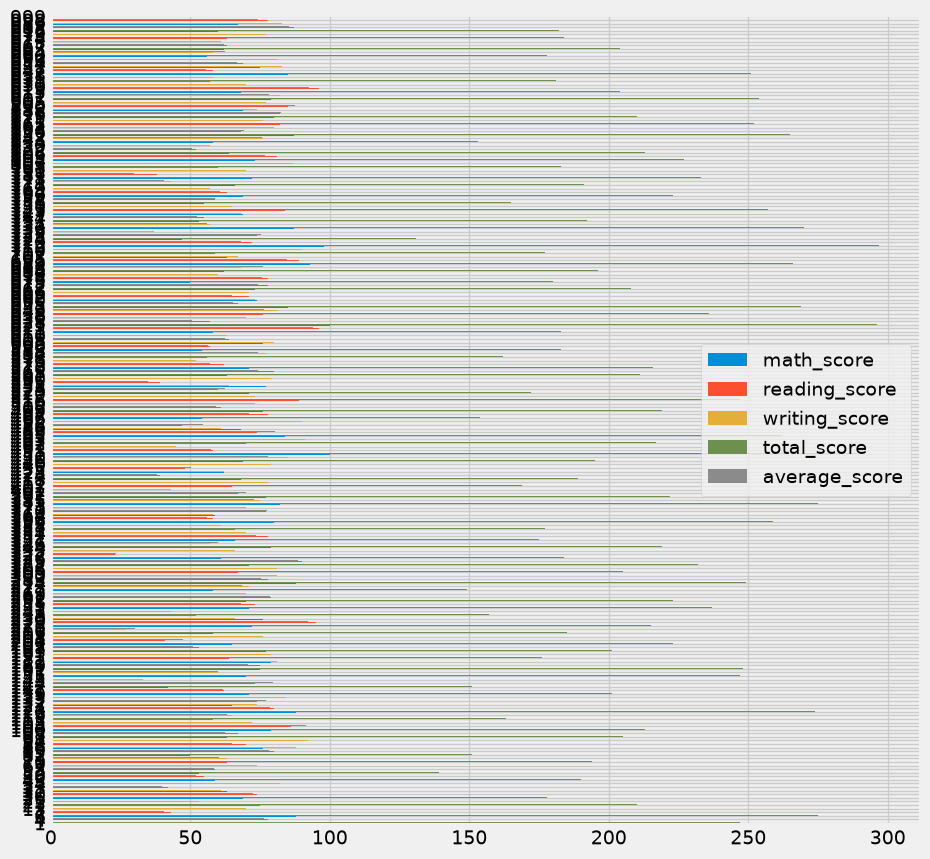

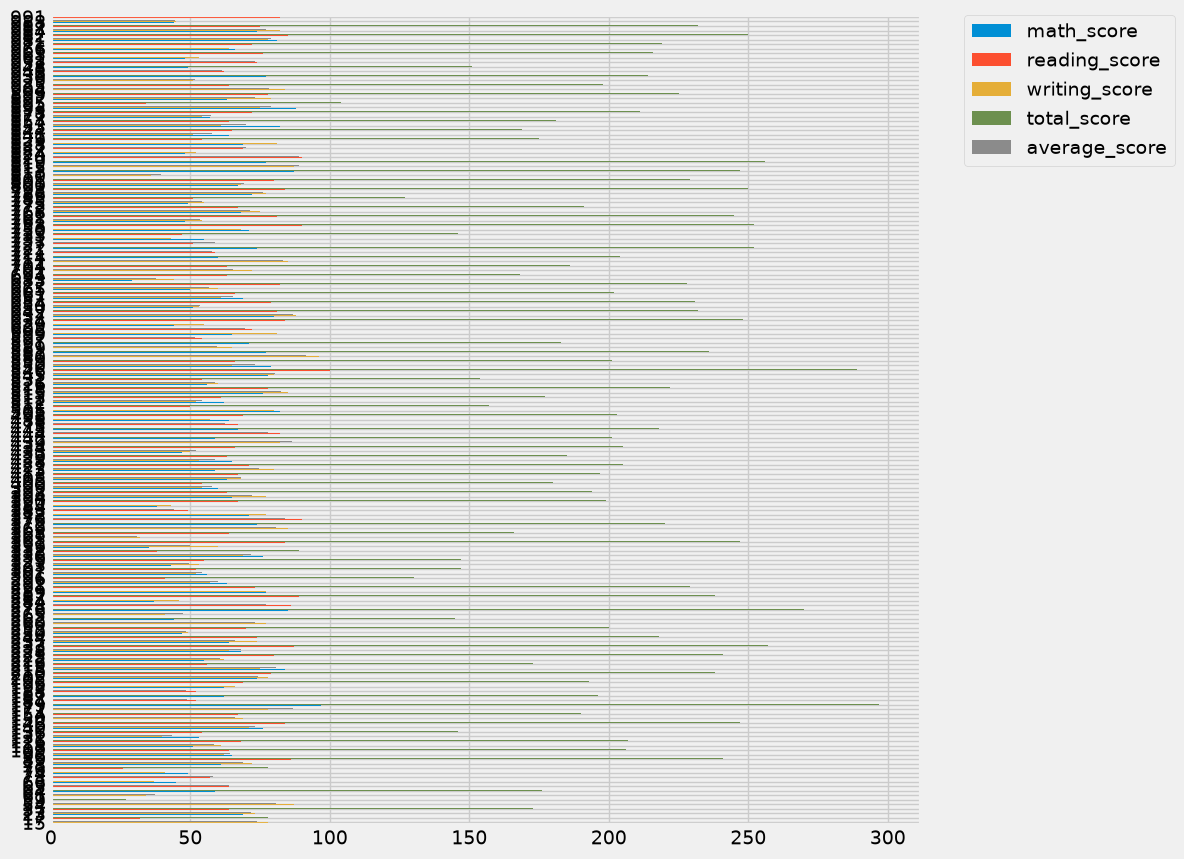

In [798]:
df.groupby('parental_level_of_education').plot(kind='barh',figsize=(10,10))
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
plt.show()

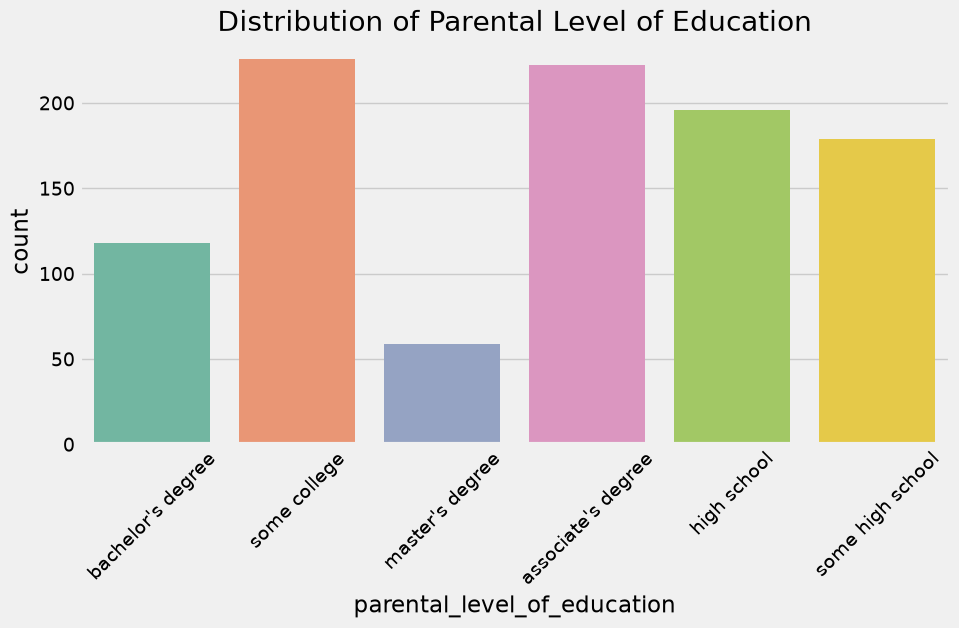

In [806]:

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='parental_level_of_education', palette='Set2')
plt.title('Distribution of Parental Level of Education')
plt.xticks(rotation=45)  # Rotates labels so they don't overlap
plt.show()

### Insights
- The score of student whose parents possess master and bachelor level education are higher than others.


### 4.4.4 LUNCH COLUMN
- Which type of lunch is most common amoung students ?
- What is the effect of lunch type on test results?


## UNIVARIATE ANALYSIS ( Which type of lunch is most common amoung students ? )

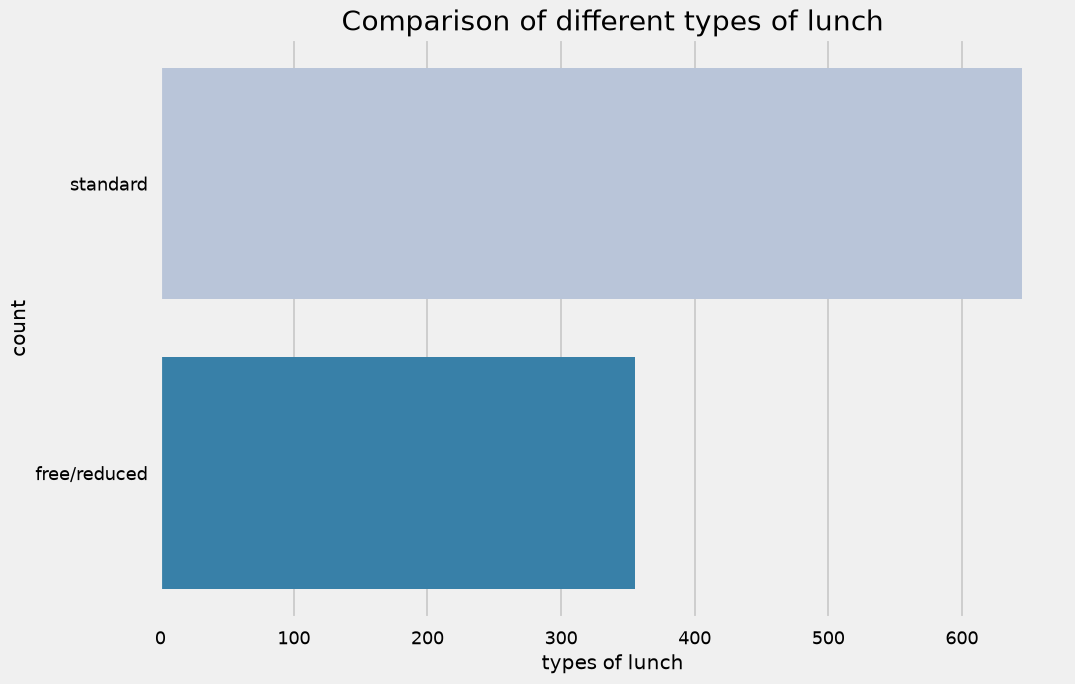

In [809]:
plt.rcParams['figure.figsize'] = (15, 9)
plt.style.use('seaborn-v0_8-talk')
sns.countplot(df['lunch'], palette = 'PuBu')
plt.title('Comparison of different types of lunch', fontweight = 30, fontsize = 20)
plt.xlabel('types of lunch')
plt.ylabel('count')
plt.show()

### Insights
- Students being served Standard lunch was more than free lunch


## BIVARIATE ANALYSIS ( Is lunch type intake has any impact on student's performance ? )

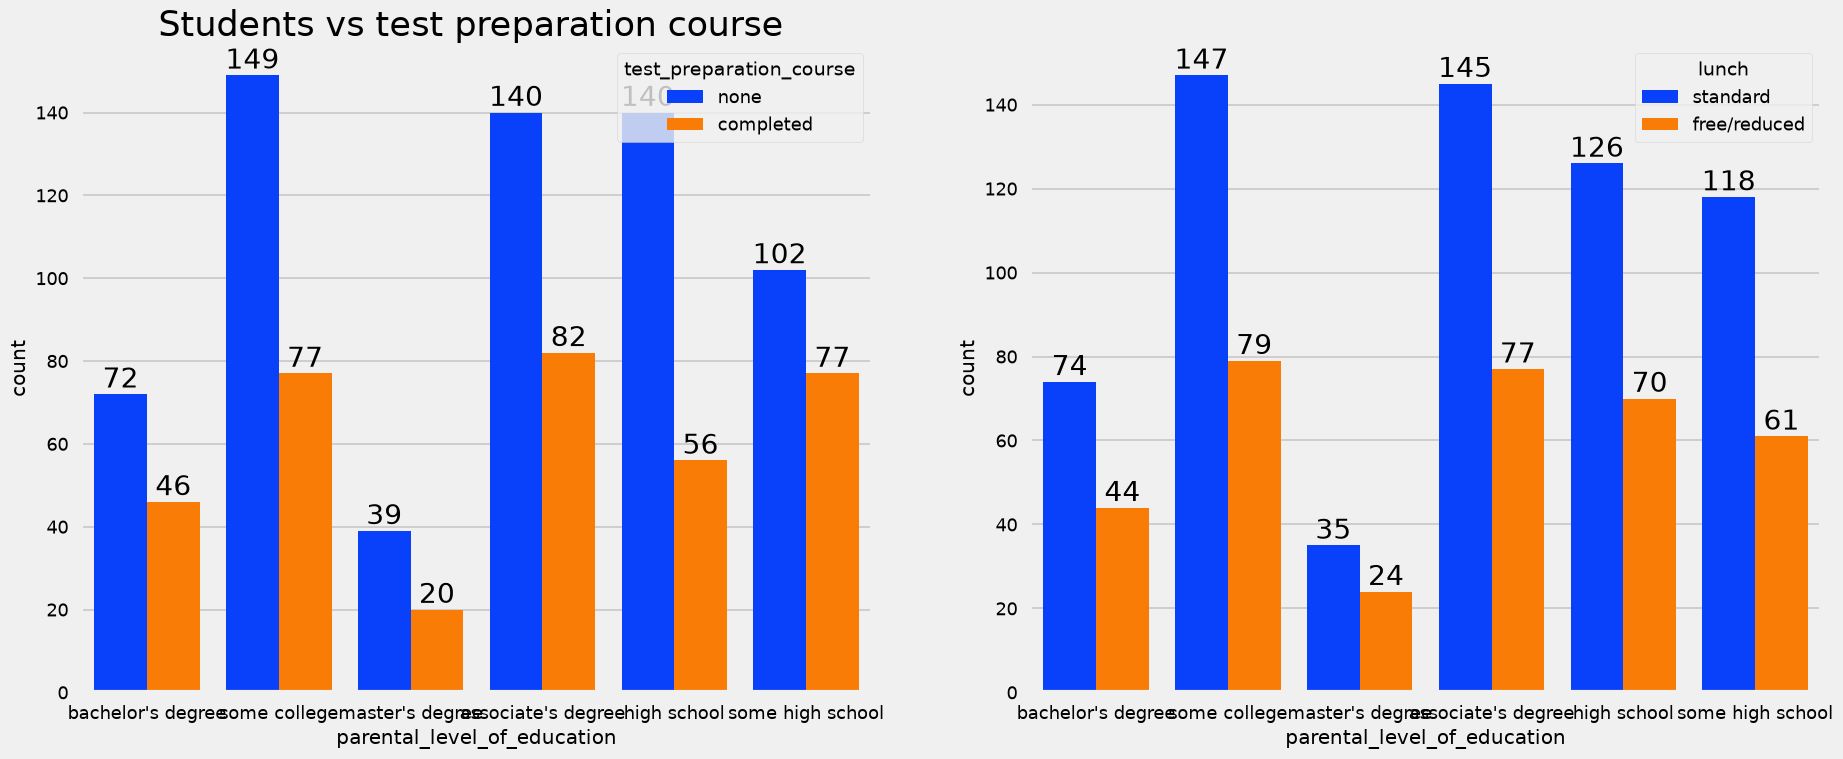

In [811]:
f,ax=plt.subplots(1,2,figsize=(20,8))
sns.countplot(x=df['parental_level_of_education'],data=df,palette = 'bright',hue='test_preparation_course',saturation=0.95,ax=ax[0])
ax[0].set_title('Students vs test preparation course ',color='black',size=25)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)
    
sns.countplot(x=df['parental_level_of_education'],data=df,palette = 'bright',hue='lunch',saturation=0.95,ax=ax[1])
for container in ax[1].containers:
    ax[1].bar_label(container,color='black',size=20)  

###Insights
- Students who get Standard Lunch tend to perform better than students who got free/reduced lunch


### 4.4.5 TEST PREPARATION COURSE COLUMN
- Which type of lunch is most common amoung students ?
- Is Test prepration course has any impact on student's performance ?


## BIVARIATE ANALYSIS ( Is Test prepration course has any impact on student's performance ? )

<Axes: xlabel='lunch', ylabel='writing_score'>

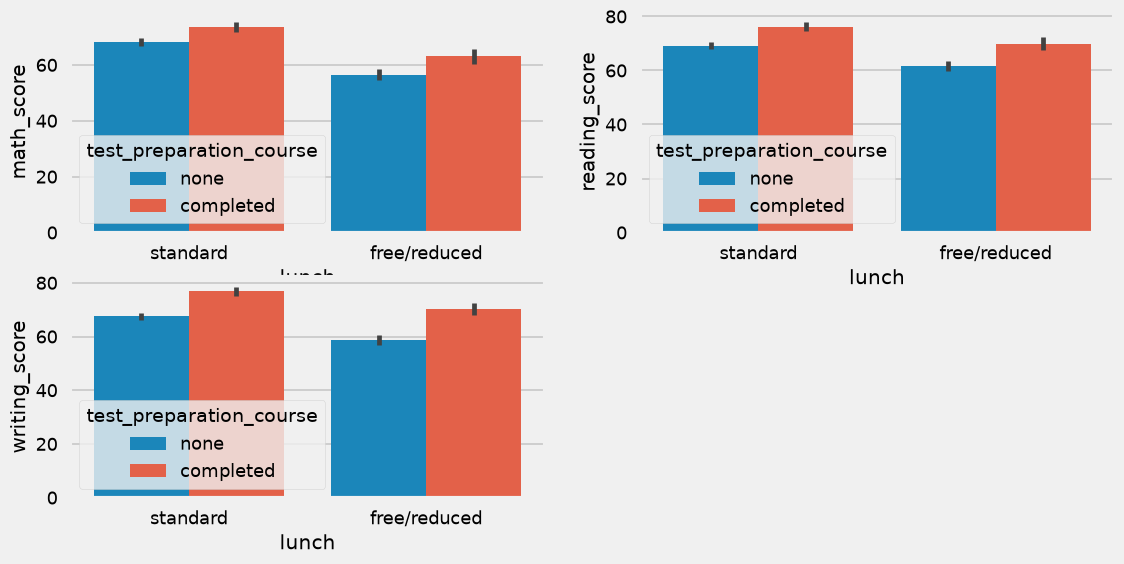

In [814]:
plt.figure(figsize=(12,6))
plt.subplot(2,2,1)
sns.barplot (x=df['lunch'], y=df['math_score'], hue=df['test_preparation_course'])
plt.subplot(2,2,2)
sns.barplot (x=df['lunch'], y=df['reading_score'], hue=df['test_preparation_course'])
plt.subplot(2,2,3)
sns.barplot (x=df['lunch'], y=df['writing_score'], hue=df['test_preparation_course'])

### Insights
- Students who have completed the Test Prepration Course have scores higher in all three categories than those who haven't taken the course


## 4.4.6 CHECKING OUTLIERS

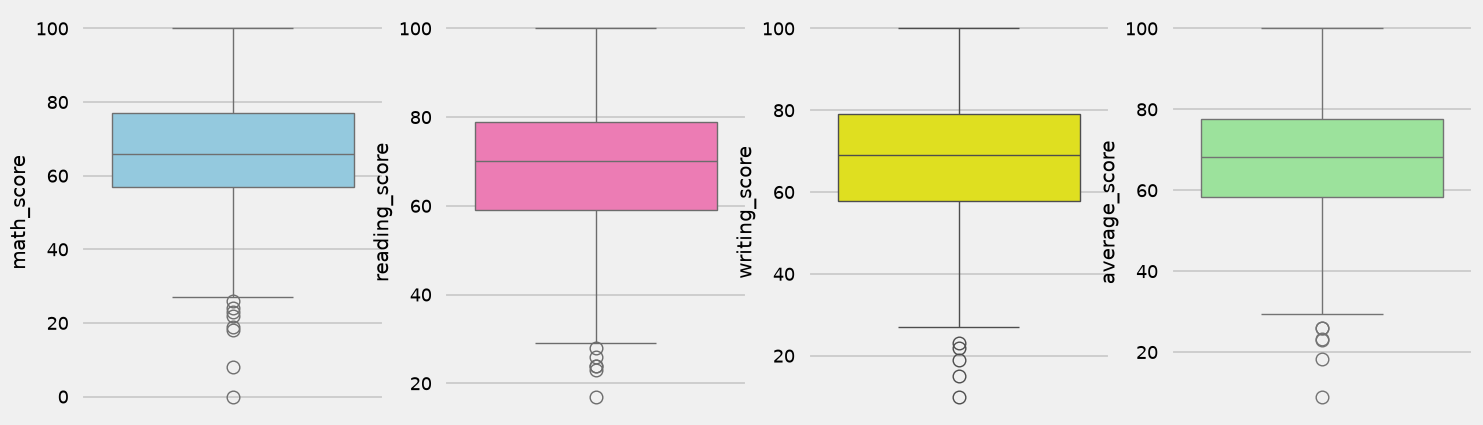

In [816]:
plt.subplots(1,4,figsize=(16,5))
plt.subplot(141)
sns.boxplot(df['math_score'],color='skyblue')
plt.subplot(142)
sns.boxplot(df['reading_score'],color='hotpink')
plt.subplot(143)
sns.boxplot(df['writing_score'],color='yellow')
plt.subplot(144)
sns.boxplot(df['average_score'],color='lightgreen')
plt.show()

## 4.4.7 MUTIVARIATE ANALYSIS USING PAIRPLOT

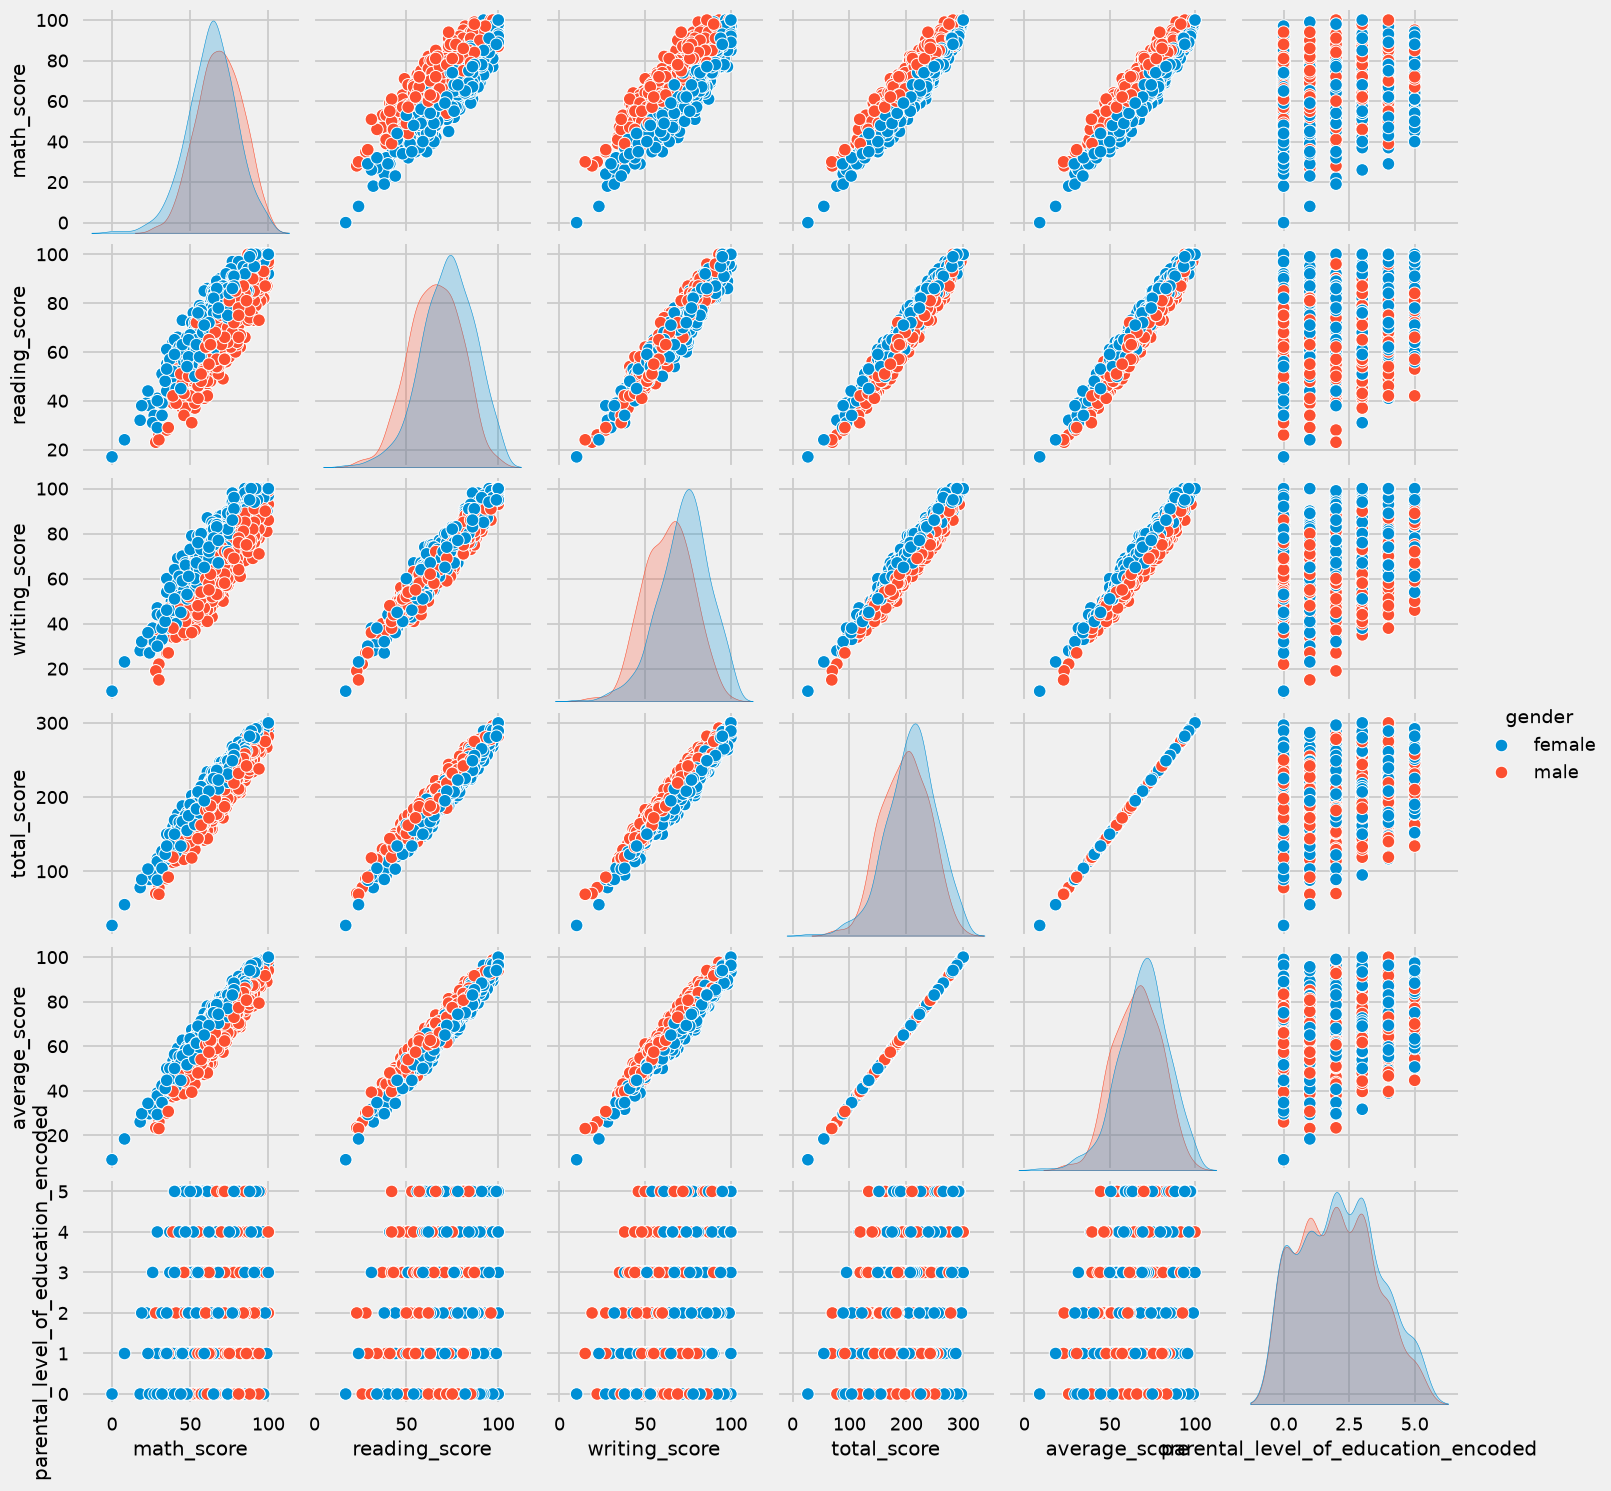

In [817]:
sns.pairplot(df,hue = 'gender')
plt.show()

### Insights
- From the above plot it is clear that all the scores increase linearly with each other.


### 5. Conclusions
- Student's Performance is related with lunch, race, parental level education
- Females lead in pass percentage and also are top-scorers
- Student's Performance is not much related with test preparation course
- Finishing preparation course is benefitial.